# Interactive figures

The spatial figures of spaclone and the main other ones have an interactive form: **one HTML file with its data
inside**. It opens by double-click in a browser, works offline, can be e-mailed, and is what a notebook shows inline.
You can zoom into a region (drag a box, scroll, pinch), switch to another sample or layer of the same kind, pick a gene,
search clones, read any point on hover, and count what lies inside a box or a free shape.

This notebook

1. opens all six public AIR-SPACE lymph nodes (Mock to day 21) in the explorer, with the sample switcher and the gene
   picker, and saves it as one file;
2. checks the numbers of a selection in Python;
3. shows one figure inline and saves a few others;
4. says how the files behave offline, in notebooks and on GitHub.

**Data.** AIR-SPACE (Jiang et al., *PNAS* 2026; GEO GSE286452), downloaded once by `spaclone.datasets.airspace`
(`pip install "spaclone[datasets]"`). Nothing else is needed: the interactive figures are part of spaclone.

In [1]:
import warnings
from importlib.metadata import version
from pathlib import Path

import pandas as pd
from IPython.display import Image

import spaclone
from spaclone import bcr, gex, io, pl
from spaclone.pl import interactive as I

spaclone.check_install(require=("datasets", "interactive"))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
print("spaclone", spaclone.__version__, "| pandas", version("pandas"), "| anndata", version("anndata"))
OUT = Path("interactive_figures")  # the figure files are written here
OUT.mkdir(exist_ok=True)

spaclone 1.1.0 | pandas 3.1.0 | anndata 0.13.4


## Six lymph nodes in one file

Each node is read with its transcriptome; germinal centres and the plasma-cell area are called from gene expression,
and the CSR / SHM hotspot workflow runs with the package defaults (as in tutorial 07).

In [2]:
DAYS = ["Mock", "D3", "D7", "D10", "D14", "D21"]
data = {day: io.read_airspace(*spaclone.datasets.airspace(day), alignments=True) for day in DAYS}
for sa in data.values():
    gex.call_regions(sa.gex, kind="germinal_centre")
    gex.call_regions(sa.gex, kind="plasma_cell")
hot = {day: bcr.hotspot_workflow(sa) for day, sa in data.items()}
pd.DataFrame({day: {"records": len(sa.air), "beads in tissue": int(sa.gex.obs["in_tissue"].sum()),
                    "CSR hotspots": int((hot[day].csr.table.direction == "hot").sum()), "regions": len(hot[day].regions)}
              for day, sa in data.items()}).T

,records,beads in tissue,CSR hotspots,regions
Mock,12054,16642,1,1
D3,21047,25118,2,2
D7,18720,26848,0,0
D10,32792,34159,1,1
D14,25504,21477,1,1
D21,17173,23040,3,3


`spaclone.pl.explore` takes one section, or a dict of them (a sample switcher in that order), and optionally the
hotspot results (the CSR and SHM share maps with their hotspots and regions). `genes=300` (the default) embeds the 300
most variable genes of the drawn beads plus the immune marker and immunoglobulin genes found in the data; the file
grows with every gene, so the explorer of six nodes is saved to a file rather than shown here.

In [3]:
fig = pl.explore(data, hotspots=hot, genes=300)
path = fig.save(OUT / "airspace_explorer.html")
print(fig)
print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")

wrote interactive_figures/airspace_explorer.html (14.7 MB, 348 genes)
<InteractiveFigure 'spaclone_explorer': spaclone explorer · 1 panel · controls: sample, show, gene, clone · data 13.14 MB>
airspace_explorer.html: 14.7 MB


Open `interactive_figures/airspace_explorer.html` in a browser. Above the map: the **sample** switcher (Mock to
D21), **show** (isotype class, switched / unswitched, BCR / TCR, chain, clones, reads, the CSR and SHM share maps, cell
type, transcriptome regions, gene expression, UMIs), the **gene** box (type a few letters: matching genes are listed;
Enter picks one; an unknown name is reported, not drawn) and the **clone** search. The tools on the right pan, zoom to a
box, select a box or a free shape, reset and save a PNG of the view. The legend shows or hides a category (double-click:
only that one); the outline legend shows or hides the hotspots and regions; click a region to zoom to it.

This is the picture a viewer without scripts gets, the first view of the figure:

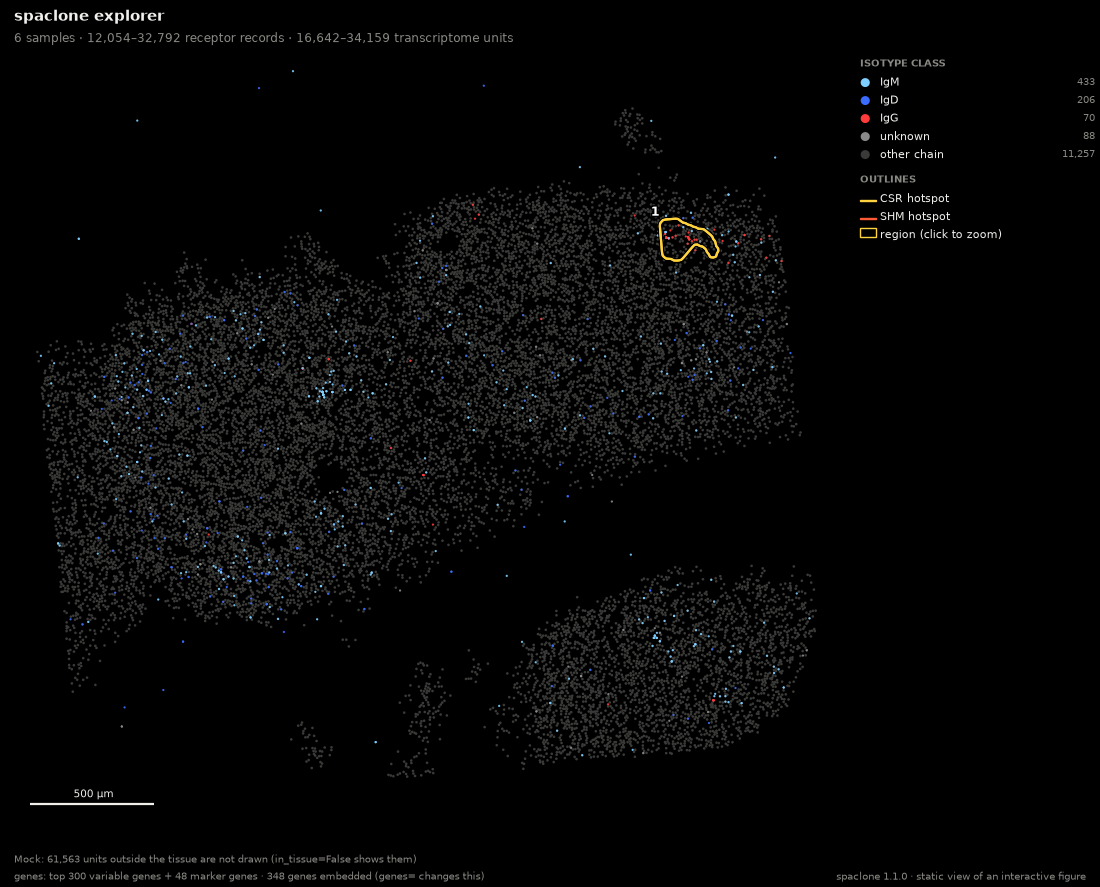

In [4]:
Image(fig.to_png(), width=900)

## The numbers of a selection, in Python

The side panel counts what lies inside a selection from the data in the file. `fig.summary` computes the same
numbers in Python, for a box or a polygon in the figure's coordinates (micrometres after the section's rotation; the
panel's home view of each sample is in `fig.spec`):

In [5]:
x0, x1, y0, y1 = fig.spec["panels"][0]["home_map"]["D21"]
box = (x0 + 0.3 * (x1 - x0), x0 + 0.6 * (x1 - x0), y0 + 0.2 * (y1 - y0), y0 + 0.5 * (y1 - y0))
fig.summary(box=box, state={"sample": "D21", "color": "isotype"}).round(3)

,layer,unit,quantity,value,n
0,isotype class,records,count,3737.000,3737
1,isotype class,records,clones,951.000,3737
2,isotype class,records,isotype (heavy chains): IgG,0.952,786
3,isotype class,records,isotype (heavy chains): IgM,0.036,786
4,isotype class,records,isotype (heavy chains): IgD,0.013,786
5,isotype class,records,isotype (heavy chains): IgE,0.000,786
6,isotype class,records,isotype (heavy chains): IgA,0.000,786
7,isotype class,records,isotype (heavy chains): unknown,0.000,786
8,isotype class,records,chain: IGK,0.670,3737
9,isotype class,records,chain: IGH,0.213,3737


The "copy shape (µm)" button of the figure copies the same shape in the section's original micrometres, ready for
`matplotlib.path.Path(shape).contains_points(...)` on the receptor table.

## One figure inline, others in files

A small figure can be shown inline: in JupyterLab and Notebook 7 it is interactive (VS Code and Colab also run scripts
in outputs); where scripts do not run (an untrusted notebook, nbconvert to PDF) the output shows its picture. The hotspot overview of day 21, the
interactive form of `pl.hotspot_overview` (click a numbered window, or pick a region, to zoom both maps to it):

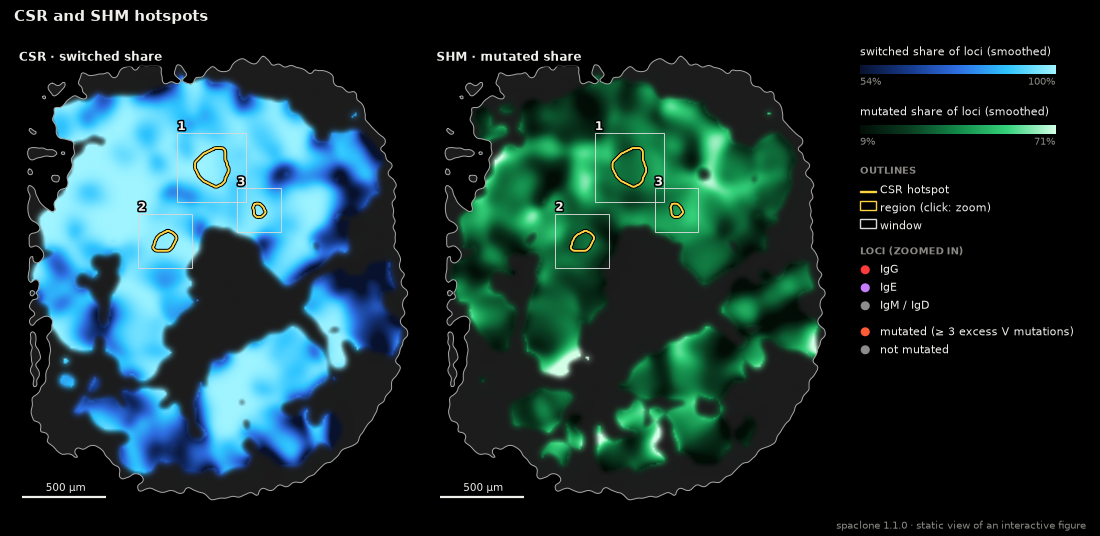

In [6]:
I.hotspot_overview(hot["D21"])

Every interactive form takes the data arguments of its static function. A few more, saved to files:

In [7]:
d21 = data["D21"]
figs = {
    "atlas": I.hotspot_atlas(hot["D21"]),
    "csr_map": I.csr_map(hot["D21"]),
    "records": I.spatial_records(d21, color="locus"),
    "clones": I.clone_map(d21.air),
    "regions": I.gex_regions(d21.gex[d21.gex.obs["in_tissue"].to_numpy(bool)]),
}
sizes = {}
for name, f in figs.items():
    p = f.save(OUT / f"{name}.html")
    sizes[name] = round(p.stat().st_size / 1e6, 2)
pd.Series(sizes, name="MB")

wrote interactive_figures/atlas.html (1.5 MB)


wrote interactive_figures/csr_map.html (1.4 MB)


wrote interactive_figures/records.html (2.7 MB)


wrote interactive_figures/clones.html (1.0 MB)


wrote interactive_figures/regions.html (1.9 MB)


atlas      1.53
csr_map    1.42
records    2.69
clones     0.96
regions    1.92
Name: MB, dtype: float64

## How many genes

The gene picker carries what `genes=` asks for: a number of variable genes (plus markers), a list of names, `"all"`
or `None`. Integer counts are stored exactly and the figure computes log1p(counts per 10,000) itself; the values menu
switches to the raw counts. More genes make a larger file:

In [8]:
rows = []
for genes in (None, 50, 300, "all"):
    f = pl.explore(d21, genes=genes)
    rows.append({"genes": str(genes), "embedded": len(f.spec["tables"][f.spec["genes"]["D21"]["names"]]) if f.spec.get("genes") else 0,
                 "file (MB)": round(f.nbytes / 1e6, 1)})
pd.DataFrame(rows)

,genes,embedded,file (MB)
0,None,0,2.7
1,50,106,2.9
2,300,348,3.1
3,all,31053,11.8


## Saving and sharing

* `fig.save("x.html")` writes one file: the figure, its data and the drawing code (spaclone's own; no third-party
  script, no network access). It opens offline, from a USB stick or an e-mail attachment.
* The file holds the data it shows (positions, clone ids, CDR3s, gene counts): share it as you would share the data.
* `fig.save("x.html", include_js="spaclone-figure.js")` writes the drawing code once next to the figures of a folder;
  `include_js="cdn"` loads it from the network instead (smaller files that need a connection).
* In a notebook, a figure larger than `I.options.notebook_max_mb` (20 MB) is shown as its picture with a line saying to
  save it, so the notebook stays small.
* In a notebook from elsewhere that you have not trusted (`jupyter trust notebook.ipynb`), the outputs show the
  pictures; the interactive figures come back when the notebook runs in Jupyter. For a notebook meant to be read on
  GitHub, also show each figure's picture as an image output (`Image(fig.to_png())`, as above).

The [interactive figures](../interactive.md) page lists where the figures work, their limits and the interactive form of every plotting
function.